# [Lab Session 3](fourier.ipynb)


In [1]:
import numpy as np
import matplotlib.pyplot as plt

from skimage.transform import resize

**[Task 1 (a).]()** Load the first image, resize it to (256, 256) and display it.


In [2]:
cell_img = plt.imread('data/cells.png')
cell_resized = cell_img.resize(256, 256)
plt.imshow(cell_img)

**[Task 1 (b).]()** Apply the fast Fourier transform and check the data type of the result.


dtype('complex128')

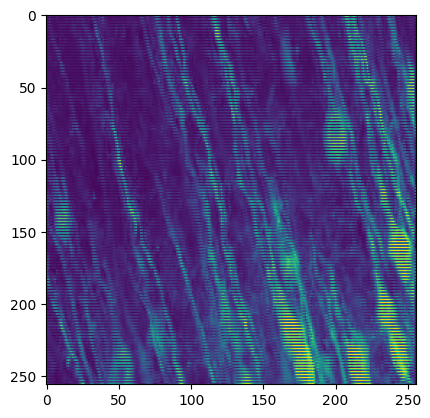

In [3]:
cell_ft=np.fft.fft2(cell_img)
cell_ft.dtype

In [4]:
cell_ft.real #real part of the complex number

array([[11685.81206986,   221.81293616,   453.94366721, ...,
          147.80395428,   453.94366721,   221.81293616],
       [  640.65369518,  -468.32903475,  -134.38933485, ...,
           80.21990743, -1116.77408501,   167.25766634],
       [   38.3429718 ,  -271.75873723,  -129.22335712, ...,
         -145.85923315,   -57.56715282,   439.44348519],
       ...,
       [  -12.16817252,   165.4361805 ,  -218.26727819, ...,
         -163.93743719,  -246.50978438,  -142.09256992],
       [   38.3429718 ,   439.44348519,   -57.56715282, ...,
          -28.69301166,  -129.22335712,  -271.75873723],
       [  640.65369518,   167.25766634, -1116.77408501, ...,
         -435.62992224,  -134.38933485,  -468.32903475]])

In [5]:
cell_ft.imag #imaginärer teil

array([[    0.        ,  1929.3298152 ,   893.59699332, ...,
         -741.65769559,  -893.59699332, -1929.3298152 ],
       [ 1743.27501325,    11.6059259 ,   144.89419543, ...,
          793.66307135,   120.6375587 ,  -366.89397839],
       [  968.67376955,   -91.48240371,  -250.70253948, ...,
         -332.9757022 ,  -235.76837929,   -15.04998787],
       ...,
       [ -853.5050427 ,  -101.96027274,   -28.30771319, ...,
          -85.00974182,    31.85212838,  -253.20664124],
       [ -968.67376955,    15.04998787,   235.76837929, ...,
          222.9923923 ,   250.70253948,    91.48240371],
       [-1743.27501325,   366.89397839,  -120.6375587 , ...,
         -230.39675407,  -144.89419543,   -11.6059259 ]])

**[Task 1 (c).]()** Extract the phase and amplitude and display them.


In [6]:
amplitude=np.abs(cell_ft)
phase=np.angle(cell_ft)

print(amplitude)
print(phase)

[[11685.81206986  1942.03875205  1002.28760318 ...   756.2421215
   1002.28760318  1942.03875205]
 [ 1857.26813599   468.47281918   197.62292679 ...   797.7069038
   1123.27101695   403.21993791]
 [  969.43233663   286.7435116    282.04687434 ...   363.52129807
    242.694676     439.70112441]
 ...
 [  853.59177733   194.33225938   220.0952779  ...   184.6676461
    248.55911144   290.35134165]
 [  969.43233663   439.70112441   242.694676   ...   224.83081627
    282.04687434   286.7435116 ]
 [ 1857.26813599   403.21993791  1123.27101695 ...   492.80431556
    197.62292679   468.47281918]]
[[ 0.          1.45632999  1.10077243 ... -1.37408486 -1.10077243
  -1.45632999]
 [ 1.21861709  3.11681616  2.31859861 ...  1.47006292  3.03398667
  -1.14306779]
 [ 1.53123402 -2.81687718 -2.04672341 ... -1.98366637 -1.8102788
  -0.03423445]
 ...
 [-1.58505207 -0.55232722 -3.01261967 ... -2.66321549  3.01309221
  -2.08217669]
 [-1.53123402  0.03423445  1.8102788  ...  1.69876577  2.04672341
   2.8168

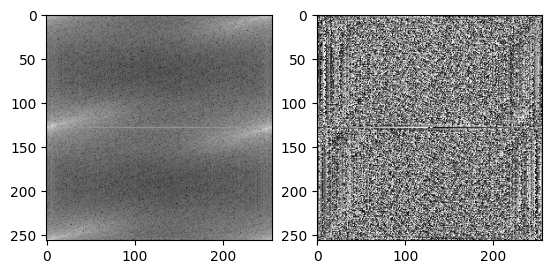

In [7]:
plt.figure()
plt.subplot(1, 2, 1)
plt.imshow(np.log(amplitude), 'gray')
plt.subplot(1, 2, 2)
plt.imshow(phase, 'gray')

**[Task 1 (d).]()** Do a shift so that zero is displayed in the center of the image and show amplitude and phase again.


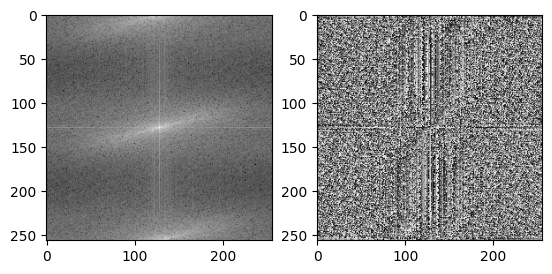

In [8]:
cells_shifted= np.fft.fftshift(cell_ft) 
ampl_shifted =np.abs(cells_shifted)
phase_shifted =np.angle(cells_shifted)
plt.figure()
plt.subplot(1, 2, 1)
plt.imshow(np.log(ampl_shifted), 'gray')
plt.subplot(1, 2, 2)
plt.imshow(phase_shifted, 'gray')

**[Task 1 (e).]()** Apply the inverse FFT and display the restored image.


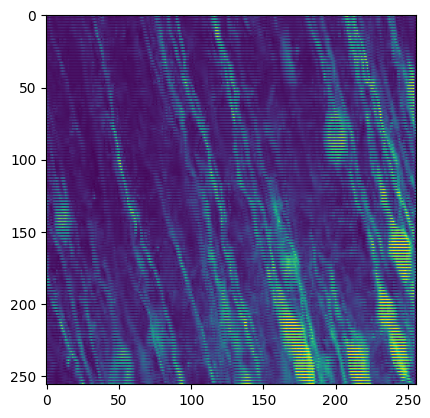

In [9]:
restore1= np.fft.ifftshift(cells_shifted)
restore2= np.fft.ifft2(restore1)
restore3 = restore2.real
plt.imshow(restore3)

---


**[Task 2 (a).]()** Load the brain MR image.


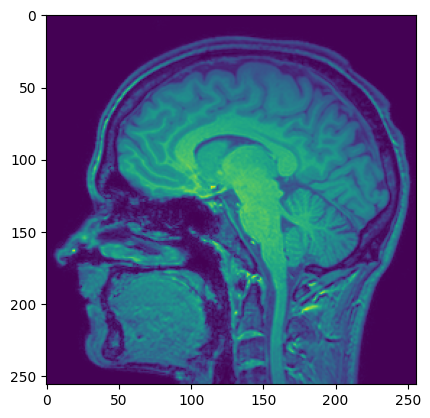

In [10]:
brain = plt.imread('data/brain_mri.png')
plt.imshow(brain)

**[Task 2 (b).]()** Apply the FFT, do a shift, extract amplitude and phase.


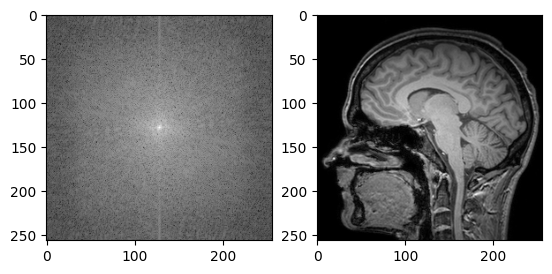

In [11]:
brain_fft= np.fft.fft2(brain)
brain_shift=np.fft.fftshift(brain_fft)
brain_amp= np.abs(brain_shift)
brain_phase= np.angle(brain_shift)

plt.figure()
plt.subplot(1, 2, 1)
plt.imshow(np.log(brain_amp), 'gray')
plt.subplot(1, 2, 2)
plt.imshow(brain, 'gray')

In [12]:
def to_complex_array(amplitude_array, phase_array):
    return amplitude_array * np.exp(1j * phase_array)

**[Task 2 (c).]()** Merge the amplitude of the brain MR image and the phase of cell image. Do the IFFT and display the resulting image.


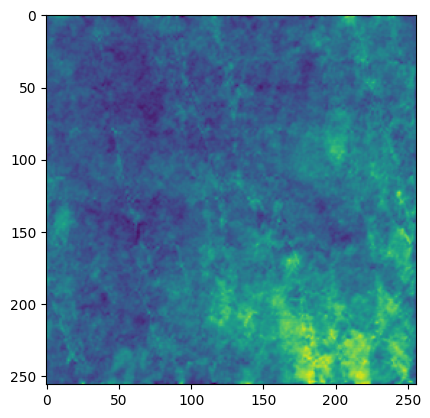

In [13]:
merged1_shifted= to_complex_array(brain_amp, phase_shifted)
merged1 =np.fft.ifftshift(merged1_shifted)
merged1_ifft=np.fft.ifft2(merged1)
plt.imshow(merged1_ifft.real)

**[Task 2 (d).]()** Repeat this with the amplitude of the cells and the phase of the brain.


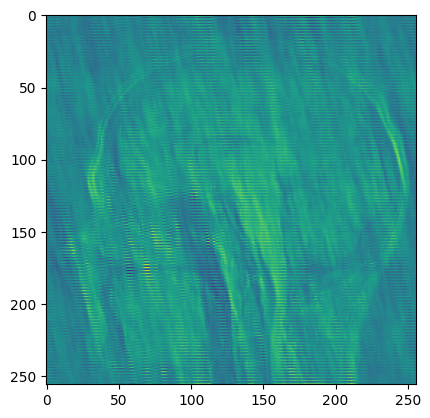

In [14]:
merged2_shifted= to_complex_array(ampl_shifted, brain_phase)
merged2 =np.fft.ifftshift(merged2_shifted)
merged2_ifft=np.fft.ifft2(merged2)
plt.imshow(merged2_ifft.real)
# amplitude carries more information

---


**[Task 3 (a).]()** Create a lowpass filter mask.


In [15]:
filter_window_size = 50

In [16]:
brain.shape

(256, 256)

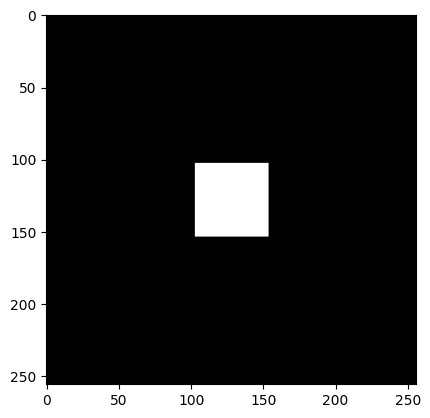

In [17]:
low_pass_filter= np.zeros((256, 256))
low_pass_filter[128-filter_window_size//2: 129 + filter_window_size//2, 128-filter_window_size//2: 129 + filter_window_size//2]=1 # //2 damit eine ganze zahl rauskommt
plt.imshow(low_pass_filter, 'grey')

**[Task 3 (b).]()** Create a highpass filter maks.


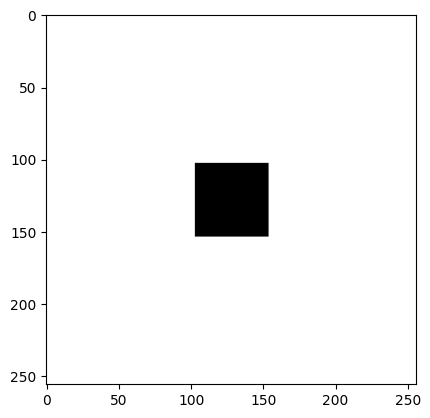

In [18]:
high_pass_filter = 1-low_pass_filter
plt.imshow(high_pass_filter, 'grey')

**[Task 3 (c).]()** Apply the lowpass and highpass filter mask to the amplitude of the brain and display the results.


/tmp/ipykernel_2029/2645537681.py:9: RuntimeWarning: divide by zero encountered in log
  plt.imshow(np.log(brain_low_filtered), 'gray')
/tmp/ipykernel_2029/2645537681.py:11: RuntimeWarning: divide by zero encountered in log
  plt.imshow(np.log(brain_high_filtered), 'gray')


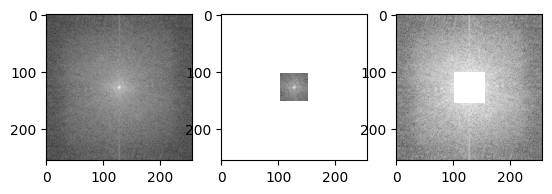

In [19]:
brain_amp
brain_low_filtered = brain_amp * low_pass_filter
brain_high_filtered = brain_amp * high_pass_filter

plt.figure()
plt.subplot(1, 3, 1)
plt.imshow(np.log(brain_amp), 'gray')
plt.subplot(1, 3, 2)
plt.imshow(np.log(brain_low_filtered), 'gray')
plt.subplot(1, 3, 3)
plt.imshow(np.log(brain_high_filtered), 'gray')

**[Task 3 (d).]()** Apply the mask to the amplitude, merge the result with the phase and restore the image.


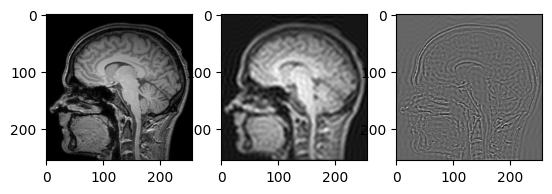

In [25]:
merged_with_filter1= to_complex_array(brain_low_filtered, brain_phase)
merged_with_filter2 = to_complex_array(brain_high_filtered, brain_phase)

#reverse the shift
shift_reverse1 = np.fft.ifftshift(merged_with_filter1)
shift_reverse2 = np.fft.ifftshift(merged_with_filter2)

#apply IFFT
ifft_applied1= np.fft.ifft2(shift_reverse1)
ifft_applied2= np.fft.ifft2(shift_reverse2)

plt.figure()
plt.subplot(1, 3, 1)
plt.imshow(brain, 'gray')
plt.subplot(1, 3, 2)
plt.imshow(ifft_applied1.real, 'gray')
plt.subplot(1, 3, 3)
plt.imshow(ifft_applied2.real, 'gray')



---


**[Task 4 (a).]()** Implement a function that computes the 2D-DFT.


In [26]:
dft = np.zeros(img.shape, dtype=complex)
M, N = img.shape

NameError: name 'img' is not defined

**[Task 4 (b).]()** Implement a function that computes the 2D-IDFT.


Due to high computational costs, we need to resize the image.


In [ ]:
test_img = resize(brain_img, (40, 40))
plt.imshow(test_img, 'gray')

NameError: name 'brain_img' is not defined

**[Task 4 (c).]()** Apply your DFT implementation to the image and display amplitude and phase.


**[Task 4 (d).]()** Reconstruct the image using your IDFT implementation and display it.


**[Task 4 (e).]()** Compare your result to the result of numpy's FFT


**[Task 4 (f).]()** Round the arrays and compare them again.


**[Task 4 (g).]()** Compare the run times of the two algorithms (your DFT and numpy's FFT)
